# Loop calling on chromatin tracing data

This tutorial calls chromatin loops from DNA FISH traces with
`uchrom.strc.loop.call_loops_axiswise_f` (also `uc.tl.call_loops`), an
independent GPU-capable implementation of the axis-wise F-test of
ArcFISH (Yu et al. 2025, bioRxiv 10.1101/2025.11.26.690837).  You will call
loops on one chromosome and on all of them at once, check the calls
against the population distance and contact maps (`uchrom.fea`,
`uchrom.pl`), tune `LoopCallerParams`, and keep the calls in
`cd.intervals` / `cd.results` and on disk.  Data: Takei et al. 2021
(*Nature* 590:344) DNA seqFISH+ in mouse ES cells at 25 kb — 20 regions of
60 loci (1.5–2.4 Mb), one per chromosome, 8,285 traces in 201 cells (4DN
`4DNFIHF3JCBY`, 22 MB).  Runtime: about a minute.

**How the caller works** (per chromosome):

1. **Per-axis variance** — for each bin pair `(i, j)` and each axis, the
   variance of `x[j] - x[i]` across traces.  Modelling the axes separately
   absorbs the anisotropic localisation error of FISH (z is usually noisier).
2. **Filter + normalise** — LOWESS on log genomic distance removes
   per-trace outliers (4 σ) and divides out the distance decay.
3. **Per-axis F-test** — a candidate pair is compared with a local
   background ring 25–50 kb away; a loop has *lower* variance than its ring.
4. **ACAT** — the three per-axis p-values are combined with weights
   ∝ 1 / (median per-trace variance of that axis).
5. **BH-FDR**, clustering of accepted pairs within 50 kb, and the
   lowest-p **summit** of each cluster.
6. **Contact filter** — a summit is kept when more than 1/2 (singletons)
   or 1/3 (clusters) of the traces bring its anchors closer than the
   typical distance of adjacent loci.

In [1]:
import shutil
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from chromdata import ChromData
import uchrom as uc

plt.rcParams["figure.dpi"] = 90


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)


def ensure_data(rel, flag):
    """``DATA / rel``; fetched with ``example-data/download_data.py --<flag>`` when absent
    (every dataset is listed in example-data/README.md)."""
    path = DATA / rel
    if not path.exists():
        print(f"{rel} not found: running example-data/download_data.py --{flag}")
        subprocess.run([sys.executable, str(DATA / "download_data.py"), f"--{flag}"], check=True)
    return path

## Load the Takei 2021 traces

`ChromData.from_fofct` reads the 4DN FISH Omics Format (FOF-CT) core table;
the loci become `cd.bins`, every detected spot a row of `cd.spots`.

In [2]:
fofct = ensure_data("4DNFIHF3JCBY.csv", "takei")
cd = ChromData.from_fofct(fofct)
print(cd)
per_chrom = pd.DataFrame({
    "loci": cd.bins.groupby("chrom", observed=True).size(),
    "traces": cd.spots.groupby("chrom", observed=True)["trace_id"].nunique(),
})
per_chrom.T

ChromData: n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']


chrom,chr1,chr10,chr11,chr12,chr13,chr14,chr15,chr16,chr17,chr18,chr19,chr2,chr3,chr4,chr5,chr6,chr7,chr8,chr9,chrX
loci,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60
traces,424,418,442,424,430,416,400,421,427,445,460,418,408,423,406,415,430,438,423,217


## Call loops on one chromosome

`chrom="chr6"` restricts the call to one chromosome.  The defaults follow
ArcFISH (`fdr_cutoff=0.1`, `pval_cutoff=1e-5`, candidates 100 kb–1 Mb
apart, background ring 25–50 kb, clustering gap 50 kb); `device="auto"`
picks CUDA, then Apple MPS, then the CPU.

In [3]:
from uchrom.strc.loop import call_loops_axiswise_f, LoopCallerParams

COLS = ["chrom1", "start1", "end1", "start2", "end2", "pval", "fdr", "cluster_size", "contact_freq"]
loops6 = call_loops_axiswise_f(cd, chrom="chr6", verbose=True)
loops6[COLS]

[loop/chr6] computing axis variance cube...


[loop/chr6] 415 traces, 60 bins; normalising...
[loop/chr6] axis weights x=0.335, y=0.330, z=0.335
[loop/chr6] median bin size 25000 bp, ring bins [1, 2]
[loop/chr6] 1397 candidates; running F-test...


,chrom1,start1,end1,start2,end2,pval,fdr,cluster_size,contact_freq
0,chr6,50300000,50325000,50525000,50550000,0.000004,0.002537,4,0.557471


The table is BEDPE-like (one row per loop summit).  It is stored, with its
provenance, under the default key `"loops.axiswise_f"`: as a typed `pair`
interval table in `cd.intervals` and as a record in `cd.results`.

In [4]:
print(cd.intervals)
rec = cd.results.record("loops.axiswise_f")
print(rec.function, "| kind:", rec.kind)
print("params:", rec.params)

IntervalStore({'loops.axiswise_f': <pair, 1 rows>})
uchrom.strc.loop.call_loops_axiswise_f | kind: intervals
params: {'cut_lo': 100000.0, 'cut_up': 1000000.0, 'inner_cut': 25000.0, 'outer_cut': 50000.0, 'fdr_cutoff': 0.1, 'pval_cutoff': 1e-05, 'gap': 50000.0, 'k_sigma': 4.0, 'frac': 0.1, 'min_cluster_size': 1}


ArcFISH's own tutorial runs `LoopCaller(fdr_cutoff=0.1)` on this chromosome
of the same dataset and reports two loops.  Which of them does this
implementation find (anchors within one 25-kb bin)?

In [5]:
# ArcFISH documentation, tutorial "Loop and domain calling" (Takei 2021 25-kb data, chr6)
arcfish_chr6 = pd.DataFrame({"start1": [50_300_000, 50_675_000], "start2": [50_525_000, 50_800_000]})


def found(ref, calls, tol=25_000):
    return [bool(((calls.start1 - a).abs().le(tol) & (calls.start2 - b).abs().le(tol)).any())
            for a, b in zip(ref.start1, ref.start2)]


arcfish_chr6.assign(called_here=found(arcfish_chr6, loops6))

,start1,start2,called_here
0,50300000,50525000,True
1,50675000,50800000,False


## Check the call against the population maps

A loop is a pair of loci that are closer than their genomic separation
predicts, i.e. a dot off the diagonal of the median distance map and of the
contact-frequency map.  `uchrom.fea.distance_map` gives the exact median
over traces (in memory or streaming over a backed store);
`contact_frequency` counts the traces in which a pair is closer than a
cutoff — here the median distance of adjacent loci, the same kind of
cutoff the caller's contact filter uses.

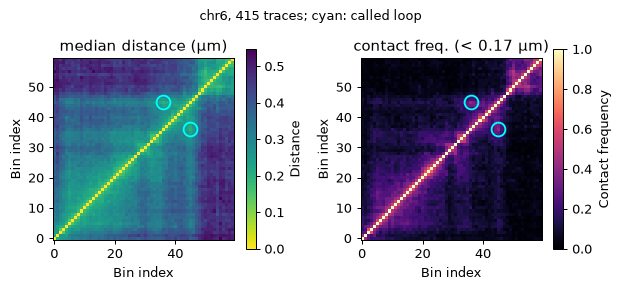

In [6]:
from uchrom.fea import contact_frequency, distance_map
from uchrom.pl import plot_contact_map, plot_distance_matrix

dm = distance_map(cd, "chr6")                               # median over traces, µm
row = {s: k for k, s in enumerate(dm.bins["start"])}        # locus start -> matrix row
cutoff = float(np.nanmedian(np.diag(dm.matrix, 1)))
cf, _, _ = contact_frequency(cd.get_chrom("chr6").to_dataframe(), threshold=cutoff, chrom="chr6")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.1))
plot_distance_matrix(dm.matrix, title=f"median distance (µm)", ax=axes[0])
plot_contact_map(cf, title=f"contact freq. (< {cutoff:.2f} µm)", ax=axes[1])
fig.suptitle(f"chr6, {dm.n_traces} traces; cyan: called loop", fontsize=10)
for ax in axes:
    for _, r in loops6.iterrows():
        i, j = row[r.start1], row[r.start2]
        ax.plot([j, i], [i, j], "o", mfc="none", mec="cyan", mew=1.5, ms=11)
plt.tight_layout(); plt.show()

## All chromosomes at once

With `chrom=None` (the default) the caller runs every chromosome and merges
the per-chromosome tables into one table under one key — here through the
flat alias `uc.tl.call_loops`, which forwards to the same function.

In [7]:
t0 = time.perf_counter()
loops = uc.tl.call_loops(cd)
print(f"{len(loops)} loops on {loops.chrom1.nunique()} of {cd.bins.chrom.nunique()} chromosomes "
      f"({time.perf_counter() - t0:.1f} s)")
loops[COLS]

5 loops on 5 of 20 chromosomes (4.5 s)


,chrom1,start1,end1,start2,end2,pval,fdr,cluster_size,contact_freq
0,chr12,63200000,63225000,63300000,63325000,1.128507e-07,1.210888e-04,1,0.626556
1,chr2,109900000,109925000,110200000,110225000,7.145620e-10,9.846665e-07,4,0.543860
2,chr4,90550000,90575000,90700000,90725000,9.020898e-08,1.159185e-04,1,0.575130
3,chr6,50300000,50325000,50525000,50550000,3.632526e-06,2.537320e-03,4,0.557471
4,chrX,75375457,75400457,75775457,75800457,9.646543e-06,1.272379e-02,1,0.555556


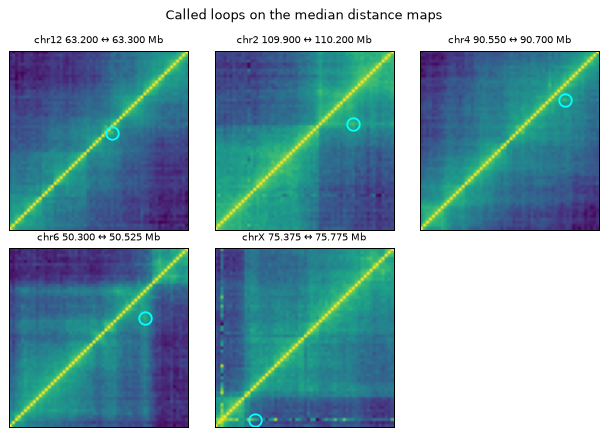

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(7, 4.9))
for ax, (_, r) in zip(axes.flat, loops.iterrows()):
    d = distance_map(cd, r.chrom1)
    k = {s: q for q, s in enumerate(d.bins["start"])}
    ax.imshow(d.matrix, cmap="viridis_r", origin="lower")
    ax.plot([k[r.start2]], [k[r.start1]], "o", mfc="none", mec="cyan", mew=1.5, ms=10)
    ax.set_title(f"{r.chrom1} {r.start1 / 1e6:.3f} ↔ {r.start2 / 1e6:.3f} Mb", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[len(loops):]:
    ax.axis("off")
fig.suptitle("Called loops on the median distance maps", fontsize=10)
plt.tight_layout()
plt.show()

**How this compares with the paper.**  On this dataset the ArcFISH preprint
reports 25 loops, 17 of them supported by Hi-C / PLAC-seq / ChIA-PET loop
lists (SnapFISH: 41 loops, 23 supported).  With the same default thresholds
this implementation is more conservative: the five summits above.  The
next section shows how the call set grows when the thresholds are relaxed.

## Tuning the thresholds

Every knob lives on `LoopCallerParams`.  `key_added=None` returns the table
without storing it, so the default call above stays in `cd.intervals`.

In [9]:
settings = {
    "default (fdr 0.1, p 1e-5)": LoopCallerParams(),
    "p 1e-3": LoopCallerParams(pval_cutoff=1e-3),
    "fdr 0.2, p 1e-3": LoopCallerParams(fdr_cutoff=0.2, pval_cutoff=1e-3),
}
counts = {name: (loops if name.startswith("default") else
                 uc.tl.call_loops(cd, params=p, key_added=None)).groupby("chrom1").size()
          for name, p in settings.items()}
table = pd.DataFrame(counts).fillna(0).astype(int)
table.loc["total"] = table.sum()
table.T

chrom1,chr12,chr13,chr16,chr19,chr2,chr3,chr4,chr6,chrX,total
"default (fdr 0.1, p 1e-5)",1,0,0,0,1,0,1,1,1,5
p 1e-3,1,2,2,1,1,4,1,2,1,15
"fdr 0.2, p 1e-3",1,2,4,2,1,4,1,2,3,20


In [10]:
relaxed6 = uc.tl.call_loops(cd, chrom="chr6", params=settings["p 1e-3"], key_added=None)
arcfish_chr6.assign(called_at_p_1e_3=found(arcfish_chr6, relaxed6))

,start1,start2,called_at_p_1e_3
0,50300000,50525000,True
1,50675000,50800000,True


## `copy=True`: leave the input untouched

By default the caller writes into `cd` and returns the table.  With
`copy=True` it returns a new `ChromData` that holds the result instead.

In [11]:
cd_chr2 = uc.tl.call_loops(cd, chrom="chr2", key_added="loops.chr2", copy=True)
print(type(cd_chr2).__name__, "intervals:", list(cd_chr2.intervals))
print("'loops.chr2' in the original:", "loops.chr2" in cd.intervals)

ChromData intervals: ['loops.axiswise_f', 'loops.chr2']
'loops.chr2' in the original: False


## Save and reload

Interval tables and result records travel with the `.chromdata.zarr`
store; a backed read loads them eagerly while the coordinates stay on disk.
For other tools, export BEDPE.

In [12]:
path = OUT / "takei2021_loops.chromdata.zarr"
if path.exists():
    shutil.rmtree(path)
cd.write(path)

back = ChromData.read(path, backed=True)
print(back.intervals)
print(back.results.record("loops.axiswise_f").created_utc)

bedpe = OUT / "takei2021_loops.bedpe"
back.intervals["loops.axiswise_f"][["chrom1", "start1", "end1", "chrom2", "start2", "end2", "score"]] \
    .to_csv(bedpe, sep="\t", header=False, index=False)
print("wrote", bedpe.relative_to(REPO))

IntervalStore({'loops.axiswise_f': <pair, 5 rows>})
2026-10-06T22:06:46+00:00
wrote tutorials/_out/takei2021_loops.bedpe


## Command line

The same caller runs from the shell on a store or a FOF-CT table, writing
BEDPE, CSV or an updated store:

```bash
python -m uchrom.strc.loop --input=data.chromdata.zarr --output=chr6_loops.bedpe --chrom=chr6
```

## Notes

- The implementation is independent of the GPL-3.0 ArcFISH source; the
  per-trace 4 σ filter, LOWESS normalisation, per-axis F-test, ACAT, BH-FDR
  and the summit / contact-frequency rules are re-implemented.
- On Apple MPS the variance cube is computed in float32 (CUDA / CPU use
  float64), which can move borderline candidates across the thresholds.
- On a backed store the caller streams over the traces (`streaming=True`,
  memory `O(n_bins²)`); the `tad_calling` tutorial shows it.

## Next steps

- `tad_calling` — ArcFISH TADs, streaming on a backed store, and projecting
  TADs / loops onto bins and spots with `uchrom.strc.enrichment`.
- `fishnet_domains` — single-allele domains with FISHnet.
- `compartment` — A/B compartments, validated against Hi-C.